# Silicon p–n junction at equilibrium

1D Poisson equation calculation in DEVSIM. In this short excercise I find $\phi(x)$ (electrostatic potential at each mesh location x), then inspect carriers (electrons and holes), charge and Electric field. I assume 300 K, Boltzmann statistics, fully ionised dopants, and no applied bias. In DEVSIM the lengths are by default in cm 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import devsim

device = "pn_device" # Name of the simulation device
region = "silicon" # Name of the region inside the device
mesh = "pn_mesh" # Name of the mesh

length_cm = 2e-4 # Size is 2 micrometres, in cm
junction_cm = 1e-4 # Position of the junction halfway through the device
spacing_cm = 2e-6 # Desired spacing in cm (20 nm)
N_A = 1e16 # Acceptor atom concentration, in cm^-3
N_D = 1e16 # Donor atom concentration, in cm^-3
T = 300.0 # Temperature in K
n_i = 1e10 # Intrinsic concentration in cm^-3, approximate at 300 K
q = 1.602176634e-19 # C: positive charge magnitude
k_B = 1.380649e-23 # J/K
permittivity = 11.7 * 8.854e-14 # Silicon permittivity in F/cm
V_t = k_B * T / q # Thermal voltage in V


## Device Setup (Mesh)

I use silicon between two end contacts.

Resetting DEVSIM
junction
right_end
 (region: silicon)
 (contact: left)
 (contact: right)


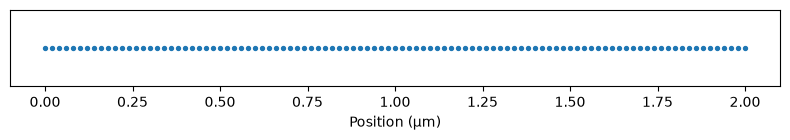

101 nodes, 0–2 µm


In [2]:
devsim.reset_devsim() # Clear previous devices before rebuilding the mesh
devsim.create_1d_mesh(mesh=mesh) # Initialize a mesh and give it a name

# Setting the boundaries and spacing of the mesh
devsim.add_1d_mesh_line(
    mesh=mesh, # Name of the mesh being modified
    pos=0.0, # Coordinates of the anchor point (left end position here)
    ps=spacing_cm, # Desired spacing towards increasing x, in cm
    tag="left_end", # Label of the anchor point
)
devsim.add_1d_mesh_line(
    mesh=mesh,
    pos=junction_cm, # Position of anchor halfway through the device
    ps=spacing_cm,
    tag="junction",
)
devsim.add_1d_mesh_line(
    mesh=mesh,
    pos=length_cm, # Right end of the device, in cm
    ps=spacing_cm,
    tag="right_end",
)

# Adding electrical contacts
devsim.add_1d_contact(
    mesh=mesh,
    name="left", # Give this new contact a name
    tag="left_end", # Place it at the position labelled "left_end"
    material="metal", # Give it an informational material label
)
devsim.add_1d_contact(
    mesh=mesh,
    name="right", # Give this new contact a name
    tag="right_end", # Place it at the position labelled "right_end"
    material="metal", # Give it an informational material label
)

# Define the silicon region
devsim.add_1d_region(
    mesh=mesh,
    region=region, # Give a name to this region
    material="Si", # Just a label; this does not choose a physical model
    tag1="left_end", # Start the region here
    tag2="right_end", # Stop the region here
)
devsim.finalize_mesh(mesh=mesh) # Finish constructing the mesh
devsim.create_device(
    mesh=mesh, # Select the finalized mesh
    device=device, # Give the simulation device a name
)

# Retrieve the node locations in the device
x_cm = np.array(devsim.get_node_model_values(
    device=device, # Which simulation device to inspect
    region=region, # Which region inside the device
    name="x", # Which node quantity to get (x is a built-in quantity)
))
x_um = x_cm * 1e4 # Convert cm to micrometres for plotting
junction_um = junction_cm * 1e4

plt.figure(figsize=(8, 1.5))
plt.scatter(x_um, np.zeros_like(x_um), s=8) # Plot the actual mesh points on a line
plt.xlabel("Position (µm)")
plt.yticks([])
plt.tight_layout()
plt.show()
print(f"{len(x_cm)} nodes, {x_um[0]:g}–{x_um[-1]:g} µm")


## Parameters and node models

Parameters are fixed inputs. `Potential` is the unknown; models calculate quantities from it.

$$C=N_D(x)-N_A(x),\quad n=n_i e^{\phi/V_t},\quad p=n_i e^{-\phi/V_t},\quad
\rho=q(p-n+C).$$

The reference is $\phi=0$ when $n=p=n_i$. The carrier model names refer to the actual equilibrium populations.

In [3]:
# Store the parameters in DEVSIM
parameters = {
    "N_A": N_A, # Acceptor concentration
    "N_D": N_D, # Donor concentration
    "JunctionPosition": junction_cm,
    "T": T,
    "ElectronCharge": q,
    "Permittivity": permittivity, # Set the Permittivity parameter name
    "n_i": n_i,
    "V_t": V_t,
}
for name, value in parameters.items():
    devsim.set_parameter(
        device=device, # Name of the existing device
        region=region, # Name of the region containing the nodes
        name=name, # Parameter's identifier
        value=value, # Numerical value of the parameter
    )

# Create the potential variable that we will solve for
devsim.node_solution(device=device, region=region, name="Potential")

# Making the doping profile, then equilibrium carrier concentrations and charge density
# ifelse(condition, value_when_true, value_when_false)
node_models = {
    "Acceptors": "ifelse(x < JunctionPosition, N_A, 0)", # Acceptors on the left side
    "Donors": "ifelse(x >= JunctionPosition, N_D, 0)", # Donors on the right side
    "NetDoping": "Donors - Acceptors", # Signed doping concentration
    "IntrinsicElectrons": "n_i * exp(Potential / V_t)", # Electron concentration n
    "IntrinsicHoles": "n_i * exp(-Potential / V_t)", # Hole concentration p
    "ChargeDensity": "ElectronCharge * (IntrinsicHoles - IntrinsicElectrons + NetDoping)", # rho
}
for name, expression in node_models.items():
    devsim.node_model(
        device=device, # Name of the existing device
        region=region, # Name of the region containing the nodes
        name=name, # Name for the quantity to be evaluated at each node
        equation=expression, # A string saying how to calculate that quantity
    )

# Retrieve the doping profiles as NumPy arrays for plotting
Acceptors = np.array(devsim.get_node_model_values(
    device=device, region=region, name="Acceptors"
))
Donors = np.array(devsim.get_node_model_values(
    device=device, region=region, name="Donors"
))
Net_Doping = np.array(devsim.get_node_model_values(
    device=device, region=region, name="NetDoping"
))


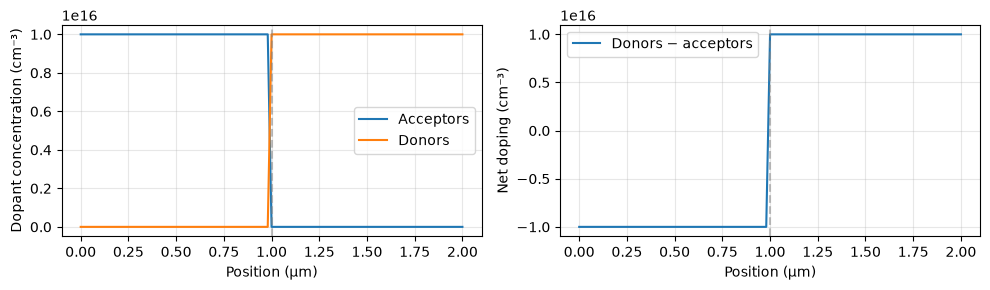

In [4]:
# Plot the individual dopant concentrations and their difference
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(x_um, Acceptors, label="Acceptors")
axes[0].plot(x_um, Donors, label="Donors")
axes[0].set_ylabel("Dopant concentration (cm⁻³)")
axes[1].plot(x_um, Net_Doping, label="Donors − acceptors")
axes[1].set_ylabel("Net doping (cm⁻³)")
for ax in axes:
    ax.set_xlabel("Position (µm)")
    ax.axvline(junction_um, color="grey", linestyle="--", alpha=0.5) # Doping junction
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()


## Edge models

$$E=-\frac{d\phi}{dx},\qquad D=\varepsilon E.$$

`@n0` and `@n1` are the ends of an edge. `Model:Potential@n0` names a derivative for Newton's method.

In [5]:
devsim.edge_from_node_model( # Make Potential@n0 and Potential@n1 available for use
    device=device, region=region, node_model="Potential"
)

# Electric field, displacement field and their derivatives
# n0 and n1 are the left and right endpoints of each edge
# EdgeInverseLength is the reciprocal length between the two nodes
edge_models = {
    "ElectricField": "(Potential@n0 - Potential@n1) * EdgeInverseLength", # E = -d phi/dx
    "ElectricField:Potential@n0": "EdgeInverseLength", # dE/d phi_0
    "ElectricField:Potential@n1": "-EdgeInverseLength", # dE/d phi_1
    "DField": "Permittivity * ElectricField", # epsilon * E
    "DField:Potential@n0": "Permittivity * EdgeInverseLength", # dD/d phi_0
    "DField:Potential@n1": "-Permittivity * EdgeInverseLength", # dD/d phi_1
}
for name, expression in edge_models.items():
    devsim.edge_model(device=device, region=region, name=name, equation=expression)


## Poisson equation

$$\nabla\cdot D-\rho=0,\qquad \frac{\partial(-\rho)}{\partial\phi}=\frac{q(n+p)}{V_t}.$$

Register DField as the flux and -ChargeDensity as the node term. Solve for Potential.

In [6]:
# Signed charge contribution and its potential derivative
poisson_models = {
    "PoissonCharge": "-ChargeDensity", # -rho, the local node contribution
    "PoissonCharge:Potential": "ElectronCharge * (IntrinsicElectrons + IntrinsicHoles) / V_t", # d(-rho)/d phi
}
for name, expression in poisson_models.items():
    devsim.node_model(device=device, region=region, name=name, equation=expression)

# Solve for the electrostatic potential phi(x) throughout the device and junction
devsim.equation(
    device=device,
    region=region,
    name="PotentialEquation", # Identifier for the equation
    variable_name="Potential", # The unknown whose values the solver will adjust and solve for
    edge_model="DField", # Use displacement field as the flux contribution
    node_model="PoissonCharge", # Use -rho as the local node contribution
    variable_update="log_damp", # Use logarithmic damping when updating potential
)


## Contacts

Ideal ohmic contacts connected to neutral bulk silicon. Neutrality is an endpoint assumption, not a consequence of "ohmic".

$$p-n+C=0\ \Rightarrow\ 2n_i\sinh(\phi/V_t)=C
\ \Rightarrow\ \phi_c=V_t\operatorname{asinh}\!\left(\frac{C}{2n_i}\right).$$

Set the boundary residual $B=\phi-\phi_c=0$; its derivative with respect to $\phi$ is 1.

In [7]:
for contact in ("left", "right"):
    boundary_model = contact + "_potential_bc" # Separate name for each contact's boundary model

    # Boundary equation: Potential - required contact potential = 0
    devsim.contact_node_model(
        device=device,
        contact=contact,
        name=boundary_model,
        equation="Potential - V_t * asinh(NetDoping / (2 * n_i))", # Residual = current potential - required potential
    )

    # Derivative of the boundary equation (residual) with respect to Potential
    devsim.contact_node_model(
        device=device,
        contact=contact,
        name=boundary_model + ":Potential",
        equation="1", # The required contact potential is constant with respect to phi
    )

    # Apply this boundary condition to the potential equation to activate it
    # The interior nodes continue to use Poisson's equation
    devsim.contact_equation(
        device=device,
        contact=contact,
        name="PotentialEquation", # Same equation identifier as in the bulk
        node_model=boundary_model, # Set this boundary residual to zero at the contact
    )


## Solve

Newton iterations adjust the nodal potentials. Carrier, charge and field models follow those values.
dc gives a time-independent solution.

In [8]:
# Solve the equilibrium potential
devsim.solve(
    type="dc", # Requests a time-independent solution
    absolute_error=1e-12, # Numerical convergence tolerance
    relative_error=1e-10, # Numerical convergence tolerance
    maximum_iterations=100, # Maximum number of Newton iterations
)


number of equations 101
Iteration: 0
  Device: "pn_device"	RelError: 1.00000e+00	AbsError: 1.15232e-01
    Region: "silicon"	RelError: 1.00000e+00	AbsError: 1.15232e-01
      Equation: "PotentialEquation"	RelError: 1.00000e+00	AbsError: 1.15232e-01
Iteration: 1
  Device: "pn_device"	RelError: 4.96675e-01	AbsError: 1.13709e-01
    Region: "silicon"	RelError: 4.96675e-01	AbsError: 1.13709e-01
      Equation: "PotentialEquation"	RelError: 4.96675e-01	AbsError: 1.13709e-01
Iteration: 2
  Device: "pn_device"	RelError: 7.98805e-01	AbsError: 1.04233e-01
    Region: "silicon"	RelError: 7.98805e-01	AbsError: 1.04233e-01
      Equation: "PotentialEquation"	RelError: 7.98805e-01	AbsError: 1.04233e-01
Iteration: 3
  Device: "pn_device"	RelError: 5.30631e-01	AbsError: 5.35665e-02
    Region: "silicon"	RelError: 5.30631e-01	AbsError: 5.35665e-02
      Equation: "PotentialEquation"	RelError: 5.30631e-01	AbsError: 5.35665e-02
Iteration: 4
  Device: "pn_device"	RelError: 3.03415e-01	AbsError: 4.34248e-

## Results

In [9]:
# Retrieve the solved potential and corresponding carrier concentrations
potential = np.array(devsim.get_node_model_values(
    device=device, region=region, name="Potential"
))
electrons = np.array(devsim.get_node_model_values(
    device=device, region=region, name="IntrinsicElectrons"
))
holes = np.array(devsim.get_node_model_values(
    device=device, region=region, name="IntrinsicHoles"
))

# Retrieve the total charge density at each node
charge_density = np.array(devsim.get_node_model_values(
    device=device, region=region, name="ChargeDensity"
))

# Retrieve the electric field on each edge
electric_field = np.array(devsim.get_edge_model_values(
    device=device, region=region, name="ElectricField"
))
x_edges_um = 0.5 * (x_um[:-1] + x_um[1:]) # Midpoints between neighbouring nodes in our 1D mesh

print(f"Contact potentials: {potential[0]:.4f}, {potential[-1]:.4f} V")
print(f"Built-in potential: {potential[-1] - potential[0]:.4f} V")


Contact potentials: -0.3572, 0.3572 V
Built-in potential: 0.7143 V


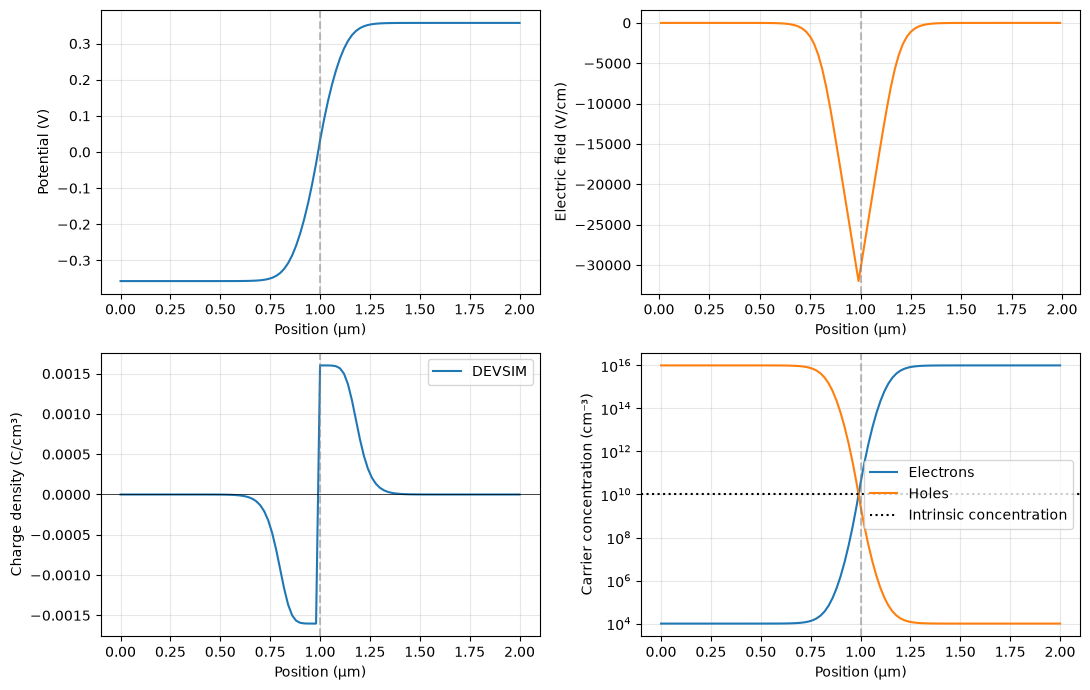

In [10]:
# Plot position in micrometres; potential, field, charge and carriers use their own units
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
potential_ax, field_ax, charge_ax, carriers_ax = axes.flat # One axis for each quantity

potential_ax.plot(x_um, potential)
potential_ax.set_ylabel("Potential (V)")

field_ax.plot(x_edges_um, electric_field, color="tab:orange") # Field values belong to edges
field_ax.set_ylabel("Electric field (V/cm)")

charge_ax.plot(x_um, charge_density, label="DEVSIM")
charge_ax.axhline(0, color="black", linewidth=0.5)
charge_ax.set_ylabel("Charge density (C/cm³)")
charge_ax.legend()

carriers_ax.semilogy(x_um, electrons, label="Electrons") # Log scale: concentrations span many orders
carriers_ax.semilogy(x_um, holes, label="Holes")
carriers_ax.axhline(n_i, color="black", linestyle=":", label="Intrinsic concentration")
carriers_ax.set_ylabel("Carrier concentration (cm⁻³)")
carriers_ax.legend()

for ax in axes.flat:
    ax.axvline(junction_um, color="grey", linestyle="--", alpha=0.5) # Doping junction
    ax.set_xlabel("Position (µm)")
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
